# Aave Holder Analysis (alongside Morpho)


## Aave vs Morpho at the holder level

Before the market breakdown, we size Aave against Morpho straight from the holder
panel (this runs today, no new export needed). We keep only real holders and, like
the Morpho notebook, restrict to operator wallets from the shared EOA cache.

In [1]:
import json
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests


def market_label(token_name, loan_token_symbol):
    """Readable market label; NONE means supplied as collateral with no borrow."""
    if loan_token_symbol == "NONE":
        return f"{token_name} (collateral only)"
    return f"{token_name} \u2192 {loan_token_symbol}"

FIG_DIR = Path("../../paper/overleaf_live/figures/meta")


def save_fig(name):
    # export to the Overleaf project when present; a no-op otherwise
    if FIG_DIR.parent.parent.exists():
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


In [2]:
EPS = 1.0
WHALE_THRESHOLD = 1_000_000  # $1M cut-off, as in the Morpho notebook

CSV_FILES = {
    "sUSDe": "from_dune/sUSDe_holders.csv",
    "sUSDS": "from_dune/sUSDS_holders.csv",
    "syrupUSDC": "from_dune/syrupUSDC_holders.csv",
}

address_cache = json.loads(Path("address_type_cache.json").read_text())
safe_cache = json.loads(Path("safe_type_cache.json").read_text())

frames = []
for token, path in CSV_FILES.items():
    df = pd.read_csv(path)
    df["wallet"] = df["wallet"].str.lower().str.strip()
    if "YBS_in_aave" not in df.columns:
        df["YBS_in_aave"] = 0.0
    for col in ["YBS_wallet_balance", "YBS_in_morpho", "YBS_in_aave", "total_YBS_exposure"]:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0).clip(lower=0.0)
    df["token"] = token
    df["is_contract"] = df["wallet"].map(address_cache)
    frames.append(df)

holders = pd.concat(frames, ignore_index=True)
holders = holders[holders["total_YBS_exposure"] > EPS]


# an operator is an EOA or a Gnosis Safe multisig (see the operators section below)
def operator_type(row):
    if row["is_contract"] == False:
        return "eoa"
    return safe_cache.get(row["wallet"], "other_contract")


def has_balance(row):
    return (row["YBS_wallet_balance"] > EPS) or (
        row["YBS_in_morpho"] + row["YBS_in_aave"] > EPS
    )


holders["optype"] = holders.apply(operator_type, axis=1)
op = holders[holders["optype"].isin(["eoa", "safe"])].copy()
op = op[op.apply(has_balance, axis=1)]

rows = []
for token, g in op.groupby("token"):
    total = g["total_YBS_exposure"].sum()
    on_aave = g["YBS_in_aave"] > EPS
    on_morpho = g["YBS_in_morpho"] > EPS
    rows.append({
        "token": token,
        "operators": len(g),
        "aave_users": int(on_aave.sum()),
        "aave_usd": g.loc[on_aave, "YBS_in_aave"].sum(),
        "aave_share_pct": round(100 * g.loc[on_aave, "YBS_in_aave"].sum() / total, 1) if total else 0.0,
        "morpho_users": int(on_morpho.sum()),
        "morpho_usd": g.loc[on_morpho, "YBS_in_morpho"].sum(),
        "morpho_share_pct": round(100 * g.loc[on_morpho, "YBS_in_morpho"].sum() / total, 1) if total else 0.0,
        "on_both": int((on_aave & on_morpho).sum()),
    })

holder_summary = pd.DataFrame(rows).sort_values("token")
holder_summary


,token,operators,aave_users,aave_usd,aave_share_pct,morpho_users,morpho_usd,morpho_share_pct,on_both
0,sUSDS,2716,0,0.000000e+00,0.0,78,5.473434e+07,1.8,0
1,sUSDe,6105,930,8.455065e+08,75.5,179,4.452847e+07,4.0,10
2,syrupUSDC,1719,0,0.000000e+00,0.0,64,1.039086e+08,40.8,0


## Aave vs Morpho: holder-level picture

For sUSDe, **Aave is the dominant venue**: about three quarters of operator (EOA and Gnosis Safe) exposure sits in
Aave versus a few percent in Morpho, and few wallets use both. sUSDS and syrupUSDC have no
Aave balances here, so the Morpho breakdown covers only a minority venue for sUSDe.


## Aave market breakdown

The cells below mirror `morpho_market_breakdown.ipynb` one to one, reading an Aave
market export produced by `from_dune/aave_market_breakdown.sql`. Run that query on
Dune and save the result as `from_dune/aave_market_breakdown_individual.csv`, then run
this section. The export has the same columns as the Morpho one
(`wallet, token_name, loan_token_symbol, lltv, collateral_balance, borrowed_amount`).

Note: Aave E-Mode is cross-collateralised, unlike Morpho's isolated markets, so the
per-borrow-asset split is descriptive of what wallets borrow, while leverage is read
per wallet against the E-Mode liquidation threshold (LLTV 0.92 for sUSDe stablecoins).

**Note on totals.** The holder-panel figure above (about \$769M sUSDe in Aave) counts EOA holders only and values collateral at panel exchange rates. The market export read below covers the full sUSDe E-Mode pool, including contract and Safe operators, so its collateral totals (about \$1.09B) are larger. The two are consistent once the EOA filter and operator scope are accounted for.


In [3]:
aave_ind = pd.read_csv("from_dune/aave_market_breakdown_individual.csv")
aave_ind["wallet"] = aave_ind["wallet"].str.lower().str.strip()
# Dune export drops the 0x prefix; restore it so joins match
aave_ind["wallet"] = aave_ind["wallet"].where(aave_ind["wallet"].str.startswith("0x"), "0x" + aave_ind["wallet"])

print(f"Rows: {len(aave_ind):,}")
print(f"Distinct wallets: {aave_ind['wallet'].nunique():,}")

Rows: 1,206
Distinct wallets: 1,167


In [4]:
EXCHANGE_RATES = { # todo take curr price from llama or other
    "syrupUSDC": 1.17,
    "sUSDe": 1.24,
    "sUSDS": 1.10,
}

aave_ind["collateral_value_usd_raw"] = aave_ind["token_name"].map(EXCHANGE_RATES) * aave_ind["collateral_balance"]

# E-Mode is cross-collateralised: split collateral across a wallet's borrow markets
# by borrowed share so market sums do not double count.
aave_ind["_wallet_debt"] = aave_ind.groupby("wallet")["borrowed_amount"].transform("sum")
aave_ind["_weight"] = np.where(
    aave_ind["_wallet_debt"] > 0,
    aave_ind["borrowed_amount"] / aave_ind["_wallet_debt"],
    1.0,
)
aave_ind["collateral_value_usd"] = aave_ind["collateral_value_usd_raw"] * aave_ind["_weight"]

(aave_ind[["wallet", "token_name", "loan_token_symbol", "collateral_balance", "collateral_value_usd"]]
    .head(10)
    .assign(loan_token_symbol=lambda d: d["loan_token_symbol"].replace("NONE", "collateral only")))

,wallet,token_name,loan_token_symbol,collateral_balance,collateral_value_usd
0,0xc468315a2df54f9c076bd5cfe5002ba211f74ca6,sUSDe,USDC,1.584258e+08,1.109436e+08
1,0xc468315a2df54f9c076bd5cfe5002ba211f74ca6,sUSDe,USDT,1.584258e+08,8.550444e+07
2,0xa9ed0db00e5c29e7e18a55db159ea33fb5fea60a,sUSDe,collateral only,9.747752e+07,1.208721e+08
3,0x6142eb927529974c5cded66dafc57cb5aaaf73ab,sUSDe,USDe,9.053734e+07,1.122663e+08
4,0x0591926d5d3b9cc48ae6efb8db68025ddc3adfa5,sUSDe,USDC,5.194224e+07,5.665133e+07
5,0x0591926d5d3b9cc48ae6efb8db68025ddc3adfa5,sUSDe,USDT,5.194224e+07,7.757042e+06
6,0xcf0a12cbd8088fc5f84ad431e71787157041cd69,sUSDe,USDe,3.910729e+07,4.849304e+07
7,0x9cbf099ff424979439dfba03f00b5961784c06ce,sUSDe,USDC,2.436676e+07,3.021478e+07
8,0x42715ba91deda3c692b9f540cee2fbb4dae78bbb,sUSDe,USDe,1.842610e+07,2.284837e+07
9,0xb3f0c00b0fc69baab5f9318b61a7b67f412a4b8b,sUSDe,collateral only,1.600000e+07,1.984000e+07


## To which markets?

In [5]:
market_summary = aave_ind.groupby(["token_name", "loan_token_symbol"]).agg(
    num_wallets=("wallet", "nunique"),
    total_collateral_usd=("collateral_value_usd", "sum"),
    total_borrowed_usd=("borrowed_amount", "sum")
).reset_index()

market_summary = market_summary.sort_values(["token_name", "total_collateral_usd"], ascending=[True, False])
market_summary.assign(loan_token_symbol=market_summary["loan_token_symbol"].replace("NONE", "collateral only"))

,token_name,loan_token_symbol,num_wallets,total_collateral_usd,total_borrowed_usd
0,sUSDe,collateral only,816,4.652965e+08,0.000000e+00
2,sUSDe,USDC,144,2.451208e+08,1.910690e+08
4,sUSDe,USDe,79,2.362691e+08,1.641206e+08
3,sUSDe,USDT,165,1.404462e+08,1.516381e+08
1,sUSDe,PYUSD,2,4.574709e+04,1.950157e+05


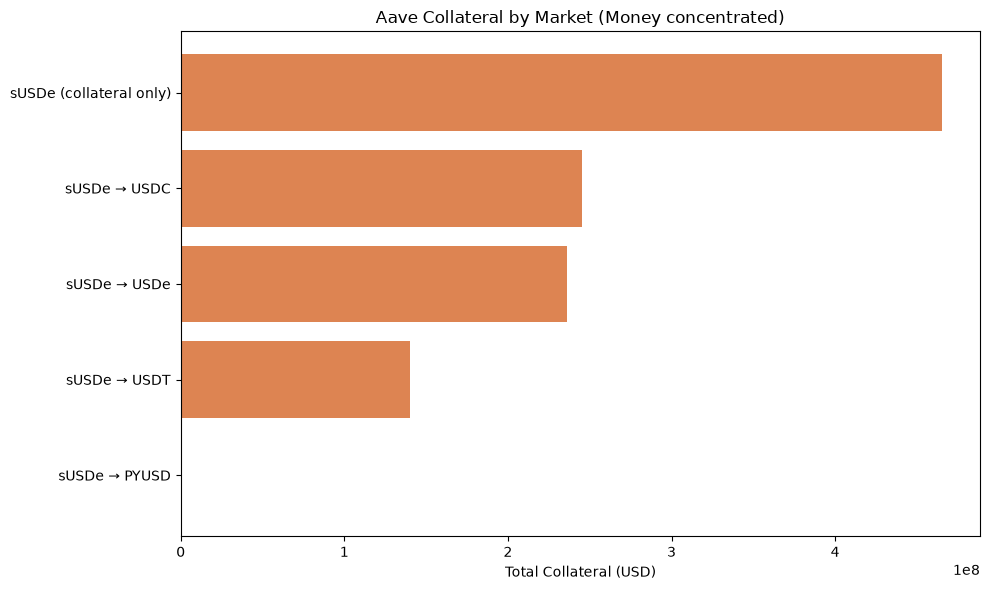

In [6]:
market_summary["market_label"] = [
    market_label(t, l) for t, l in zip(market_summary["token_name"], market_summary["loan_token_symbol"])
]

fig, ax = plt.subplots(figsize=(10, 6))

colors = {"syrupUSDC": "#4C72B0", "sUSDe": "#DD8452", "sUSDS": "#55A868"}
bar_colors = market_summary["token_name"].map(colors)

ax.barh(market_summary["market_label"], market_summary["total_collateral_usd"], color=bar_colors)
ax.set_xlabel("Total Collateral (USD)")
ax.set_title("Aave Collateral by Market (Money concentrated)")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

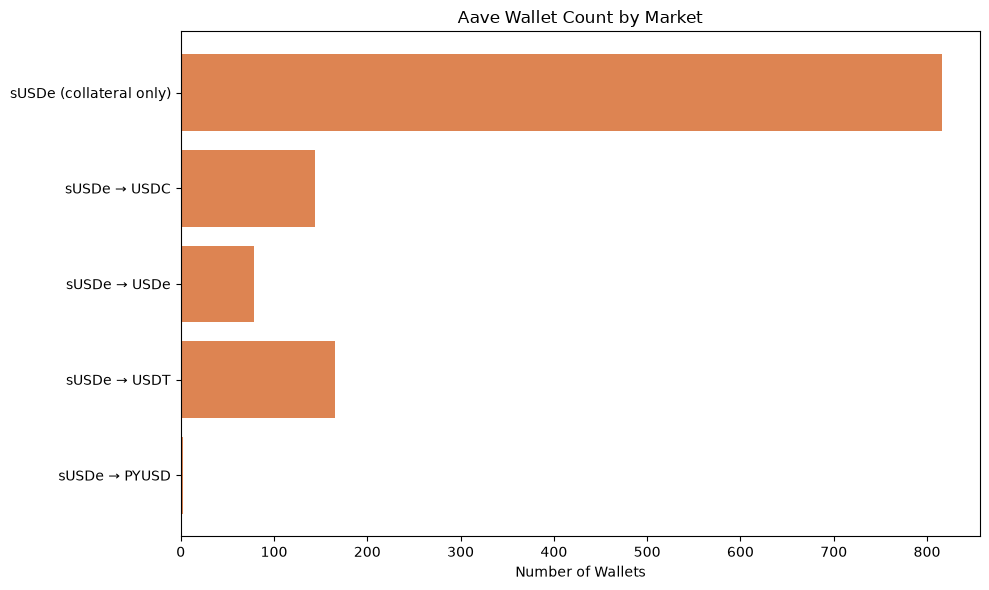

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(market_summary["market_label"], market_summary["num_wallets"], color=bar_colors)
ax.set_xlabel("Number of Wallets")
ax.set_title("Aave Wallet Count by Market")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

## What for; tied to what each wallet actually did in that market: borrowed a stablecoin against their collateral, borrowed something non-stable, or just parked collateral with no borrow at all

In [8]:
stablecoins_df = pd.read_csv("stablecoins.csv")
STABLES = (set(stablecoins_df["symbol"]) | {"USDC", "USDT", "USDe", "DAI", "sDAI"}) - {"WETH"}

def tag_archetype(row):
    if row["loan_token_symbol"] in ("NONE", None) or row["borrowed_amount"] <= 0:
        return "collateral_only"
    if row["loan_token_symbol"] in STABLES:
        return "stablecoin_borrow"
    return "non_stable_borrow"

aave_ind["market_archetype"] = aave_ind.apply(tag_archetype, axis=1)
aave_ind["market_archetype"].value_counts()

market_archetype
collateral_only      816
stablecoin_borrow    390
Name: count, dtype: int64

## Which markets and what for

All Aave collateral here is sUSDe in stablecoin E-Mode, borrowed against three stables:

| Borrow market | Wallets | Collateral | Borrowed |
|---|---|---|---|
| sUSDe / USDC | 144 | \$245.1M | \$191.1M |
| sUSDe / USDe | 79 | \$236.3M | \$164.1M |
| sUSDe / USDT | 165 | \$140.4M | \$151.6M |
| Collateral only | 816 | \$465.3M | 0 |

Of 1,206 positions, 32% loop (borrow a stable against sUSDe) and 68% hold collateral with
no borrow; non-stable borrowing is absent. Collateral is attributed across a wallet's
borrow markets by borrowed share, since E-Mode is cross-collateralised.


## Operators: EOAs and Gnosis Safe multisigs

We define an operator (and therefore a whale) as either an externally owned account (EOA)
or a Gnosis Safe multisig, because many large operators hold and loop through a Safe rather
than a plain EOA. The meta-archetype whale flags cover only EOAs, so here we additionally
detect Safes among the sUSDe holders those flags miss and fold them into the whale
definition used for the rest of this notebook. Every chart and number below is computed on
this EOA + Safe operator set.

**Detection:** a Gnosis Safe is a proxy that stores its singleton (masterCopy) address in
storage slot 0. For each unmatched contract we read slot 0 via `eth_getStorageAt` and check
whether it points at a known Safe singleton; this is version agnostic and needs one RPC
call per address. Results are cached in `safe_type_cache.json`; the shared
`address_type_cache.json` and the Morpho notebook are left untouched. Wallets that are
neither EOA nor Safe (bundlers, vaults, routers) are treated as infrastructure and left out
of the operator/whale set.


In [9]:
whale_flags = pd.read_csv("whale_flags.csv").rename(columns={"token": "token_name"})
whale_flags["wallet"] = whale_flags["wallet"].str.lower().str.strip()

# known Safe singletons (masterCopy), lowercased
KNOWN_SAFE_SINGLETONS = {
    "0xb6029ea3b2c51d09a50b53ca8012feeb05bda35a",  # 1.0.0
    "0x34cfac646f301356faa8b21e94227e3583fe3f5f",  # 1.1.1
    "0xd9db270c1b5e3bd161e8c8503c55ceabee709552",  # 1.3.0
    "0x3e5c63644e683549055b9be8653de26e0b4cd36e",  # 1.3.0 L2
    "0x41675c099f32341bf84bfc5382af534df5c7461a",  # 1.4.1
    "0x29fcb43b46531bca003ddc8fcb67ffe91900c762",  # 1.4.1 L2
}

RPC_URLS = [
    "https://ethereum-rpc.publicnode.com",
    "https://eth.drpc.org",
    "https://1rpc.io/eth",
    "https://cloudflare-eth.com",
]

SAFE_CACHE_FILE = Path("safe_type_cache.json")
safe_cache = json.loads(SAFE_CACHE_FILE.read_text()) if SAFE_CACHE_FILE.exists() else {}

address_cache = json.loads(Path("address_type_cache.json").read_text())


def _rpc(method, params):
    payload = {"jsonrpc": "2.0", "id": 1, "method": method, "params": params}
    for url in RPC_URLS:
        try:
            r = requests.post(url, json=payload, timeout=20)
            r.raise_for_status()
            data = r.json()
            if "result" in data and data["result"] is not None:
                return data["result"]
        except Exception:
            continue
    return None


def slot0_singleton(addr):
    """Return the address stored in slot 0 (Safe singleton), or None."""
    raw = _rpc("eth_getStorageAt", [addr, "0x0", "latest"])
    if not raw or len(raw) < 42:
        return None
    return "0x" + raw[-40:]


def classify_address(addr):
    """eoa | safe | other_contract, cached."""
    if addr in safe_cache:
        return safe_cache[addr]
    is_contract = address_cache.get(addr)
    if is_contract is False:
        label = "eoa"
    else:
        singleton = slot0_singleton(addr)
        if singleton is not None and singleton.lower() in KNOWN_SAFE_SINGLETONS:
            label = "safe"
        elif is_contract is True:
            label = "other_contract"
        else:
            # not in the EOA cache: fall back to code check
            code = _rpc("eth_getCode", [addr, "latest"])
            label = "other_contract" if (code and code != "0x") else "eoa"
    safe_cache[addr] = label
    return label


# Aave wallets the EOA-only flags missed
matched_wallets = set(whale_flags["wallet"])
unmatched = sorted(set(aave_ind["wallet"]) - matched_wallets)
print(f"Aave wallets not matched by EOA-only whale flags: {len(unmatched):,}")

todo = [w for w in unmatched if w not in safe_cache]
print(f"Classifying {len(todo):,} addresses via RPC (cached: {len(unmatched) - len(todo):,})...")

with ThreadPoolExecutor(max_workers=6) as ex:
    for i, _ in enumerate(ex.map(classify_address, todo), 1):
        if i % 100 == 0:
            SAFE_CACHE_FILE.write_text(json.dumps(safe_cache))
            print(f"  {i:,}/{len(todo):,}")

SAFE_CACHE_FILE.write_text(json.dumps(safe_cache))

labels = pd.Series({w: safe_cache.get(w, "eoa") for w in unmatched})
print("\nBreakdown of the unmatched Aave holders:")
print(labels.value_counts())

Aave wallets not matched by EOA-only whale flags: 359
Classifying 0 addresses via RPC (cached: 359)...

Breakdown of the unmatched Aave holders:
other_contract    233
safe              122
eoa                 4
Name: count, dtype: int64


In [10]:
susde_exposure = (
    holders.loc[holders["token"] == "sUSDe", ["wallet", "total_YBS_exposure"]]
    .groupby("wallet")["total_YBS_exposure"].max()
)

safe_wallets = [w for w in unmatched if safe_cache.get(w) == "safe"]
eoa_unmatched = [w for w in unmatched if safe_cache.get(w) == "eoa"]

extra_rows = []
for w in safe_wallets + eoa_unmatched:
    extra_rows.append({
        "wallet": w,
        "token_name": "sUSDe",
        "is_whale": bool(susde_exposure.get(w, 0.0) >= WHALE_THRESHOLD),
        "operator_type": "safe" if w in safe_wallets else "eoa",
    })
extra = pd.DataFrame(extra_rows)

flags_eoa = whale_flags.copy()
flags_eoa["operator_type"] = "eoa"
flags_op = pd.concat([flags_eoa, extra], ignore_index=True).drop_duplicates(["wallet", "token_name"], keep="first")

print(f"Safes found: {len(safe_wallets):,}  |  Safe whales (>= $1M): {int(extra.loc[extra.operator_type=='safe','is_whale'].sum())}")
print(f"Extra EOA operators recovered: {len(eoa_unmatched):,}")


def whale_collateral_share(flag_df, label):
    m = aave_ind.merge(flag_df[["wallet", "token_name", "is_whale"]], on=["wallet", "token_name"], how="left")
    m["is_whale"] = m["is_whale"].fillna(False)
    by_market = m.groupby("loan_token_symbol").apply(
        lambda g: 100 * g.loc[g["is_whale"], "collateral_value_usd"].sum() / g["collateral_value_usd"].sum()
        if g["collateral_value_usd"].sum() else 0.0
    ).round(1)
    by_market.name = label
    return m, by_market


m_eoa, share_eoa = whale_collateral_share(whale_flags, "EOA only")
m_op, share_op = whale_collateral_share(flags_op, "EOA + Safe")

comparison = pd.concat([share_eoa, share_op], axis=1)
comparison["delta"] = (comparison["EOA + Safe"] - comparison["EOA only"]).round(1)
print("\nWhale share of collateral by market (%):")
(comparison.rename(index={"NONE": "collateral only"})
    .sort_values("EOA + Safe", ascending=False))

Safes found: 122  |  Safe whales (>= $1M): 7
Extra EOA operators recovered: 4

Whale share of collateral by market (%):


,EOA only,EOA + Safe,delta
loan_token_symbol,,,
USDC,73.8,96.9,23.1
USDe,93.3,93.7,0.4
USDT,77.0,82.5,5.5
collateral only,76.7,80.8,4.1
PYUSD,0.0,0.0,0.0


Whale positions  EOA only: 69   EOA + Safe: 77
Whale collateral share  EOA only: 79.7%   EOA + Safe: 87.4%


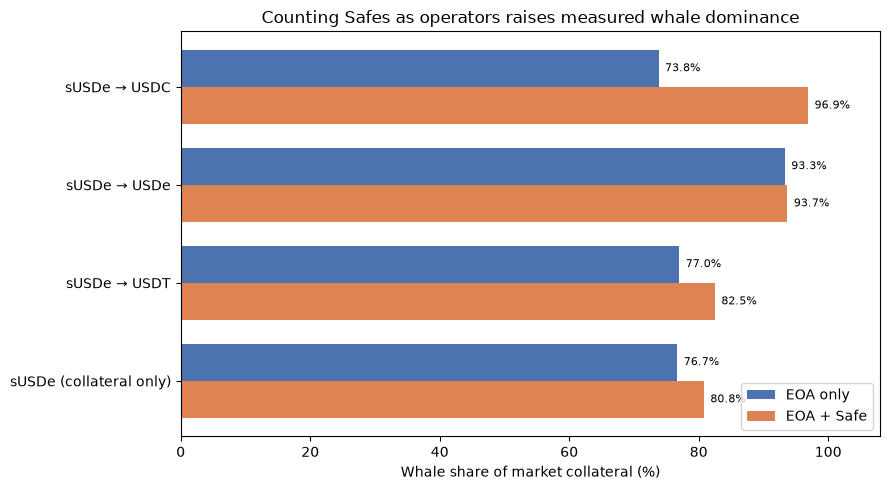

In [11]:
n_whales_eoa = m_eoa["is_whale"].sum()
n_whales_op = m_op["is_whale"].sum()
share_eoa_total = 100 * m_eoa.loc[m_eoa["is_whale"], "collateral_value_usd"].sum() / m_eoa["collateral_value_usd"].sum()
share_op_total = 100 * m_op.loc[m_op["is_whale"], "collateral_value_usd"].sum() / m_op["collateral_value_usd"].sum()

print(f"Whale positions  EOA only: {int(n_whales_eoa)}   EOA + Safe: {int(n_whales_op)}")
print(f"Whale collateral share  EOA only: {share_eoa_total:.1f}%   EOA + Safe: {share_op_total:.1f}%")

plot = comparison.drop(index="PYUSD", errors="ignore").sort_values("EOA + Safe")
y = np.arange(len(plot))
h = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y + h/2, plot["EOA only"], height=h, color="#4C72B0", label="EOA only")
ax.barh(y - h/2, plot["EOA + Safe"], height=h, color="#DD8452", label="EOA + Safe")
ax.set_yticks(y)
ax.set_yticklabels([market_label("sUSDe", s) for s in plot.index])
ax.set_xlabel("Whale share of market collateral (%)")
ax.set_xlim(0, 108)
ax.set_title("Counting Safes as operators raises measured whale dominance")
for yi, a, b in zip(y, plot["EOA only"], plot["EOA + Safe"]):
    ax.text(a + 1, yi + h/2, f"{a:.1f}%", va="center", fontsize=8)
    ax.text(b + 1, yi - h/2, f"{b:.1f}%", va="center", fontsize=8)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# from here on, "whale"/operator = EOA or Gnosis Safe above the $1M threshold
whale_flags = flags_op


### Whale definition applied below

From here on, a whale is an EOA or Gnosis Safe operator above the \$1M threshold. Counting
Safes rather than dropping them recovers the whale positions the EOA-only filter missed and
raises the measured whale share of Aave sUSDe collateral (comparison above). Every chart
and figure in the rest of this notebook uses this EOA + Safe definition.


## Q: What whales are doing?

In [12]:
aave_ind_whales = aave_ind.merge(whale_flags, on=["wallet", "token_name"], how="left")

print(aave_ind_whales["is_whale"].isna().sum(), "rows with no whale match")
aave_ind_whales["is_whale"].value_counts(dropna=False)

240 rows with no whale match


is_whale
False    889
NaN      240
True      77
Name: count, dtype: int64

In [13]:
archetype_by_whale = aave_ind_whales.groupby(["is_whale", "market_archetype"]).size().unstack(fill_value=0)
archetype_by_whale_pct = archetype_by_whale.div(archetype_by_whale.sum(axis=1), axis=0).round(3) * 100
archetype_by_whale_pct

market_archetype,collateral_only,stablecoin_borrow
is_whale,,
False,70.1,29.9
True,57.1,42.9


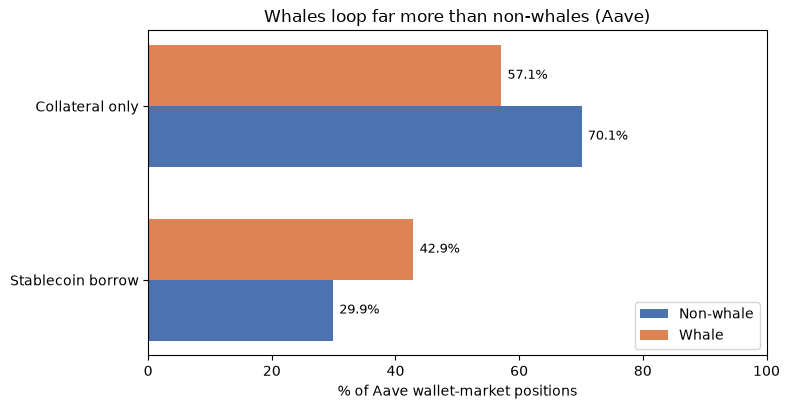

In [14]:
archetypes = [a for a in ["collateral_only", "non_stable_borrow", "stablecoin_borrow"]
              if a in archetype_by_whale_pct.columns]
nonwhale = archetype_by_whale_pct.loc[False, archetypes]
whale = archetype_by_whale_pct.loc[True, archetypes]

y = np.arange(len(archetypes))
h = 0.35

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(y + h/2, nonwhale, height=h, color="#4C72B0", label="Non-whale")
ax.barh(y - h/2, whale, height=h, color="#DD8452", label="Whale")
ax.set_yticks(y)
ax.set_yticklabels([a.replace("_", " ").capitalize() for a in archetypes])
ax.set_xlabel("% of Aave wallet-market positions")
ax.set_title("Whales loop far more than non-whales (Aave)")
ax.invert_yaxis()
for i, (nv, wv) in enumerate(zip(nonwhale, whale)):
    ax.text(nv + 1, i + h/2, f"{nv:.1f}%", va="center", fontsize=9)
    ax.text(wv + 1, i - h/2, f"{wv:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("aave-looping-archetype-mix.png")
plt.show()

In [15]:
whale_market_share = aave_ind_whales.groupby(["token_name", "loan_token_symbol"]).apply(
    lambda g: pd.Series({
        "whale_collateral_usd": g.loc[g["is_whale"] == True, "collateral_value_usd"].sum(),
        "total_collateral_usd": g["collateral_value_usd"].sum(),
    })
).reset_index()

whale_market_share["whale_share_pct"] = (
    whale_market_share["whale_collateral_usd"] / whale_market_share["total_collateral_usd"] * 100
).round(1)

(whale_market_share.sort_values("total_collateral_usd", ascending=False)
    .assign(loan_token_symbol=lambda d: d["loan_token_symbol"].replace("NONE", "collateral only")))

,token_name,loan_token_symbol,whale_collateral_usd,total_collateral_usd,whale_share_pct
0,sUSDe,collateral only,3.758754e+08,4.652965e+08,80.8
2,sUSDe,USDC,2.375923e+08,2.451208e+08,96.9
4,sUSDe,USDe,2.212715e+08,2.362691e+08,93.7
3,sUSDe,USDT,1.158680e+08,1.404462e+08,82.5
1,sUSDe,PYUSD,0.000000e+00,4.574709e+04,0.0


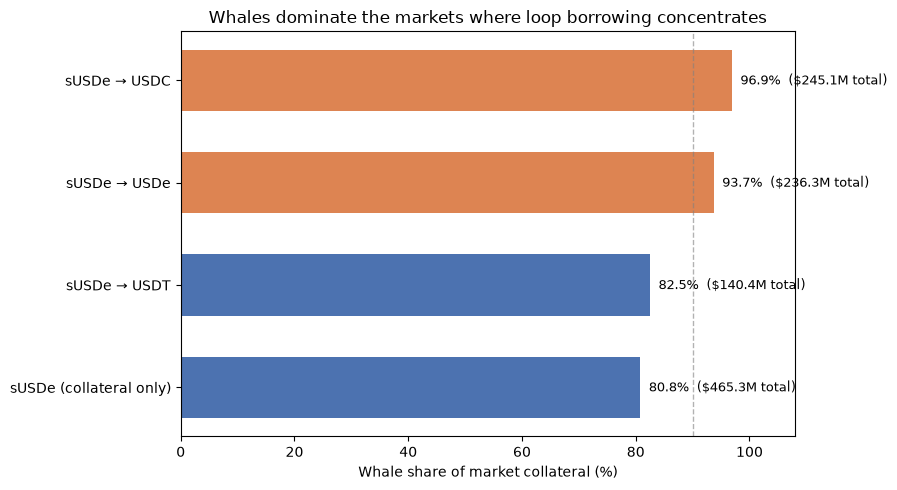

In [16]:
dom = whale_market_share[whale_market_share["total_collateral_usd"] > 1_000_000].copy()
dom = dom.sort_values("whale_share_pct", ascending=True)
dom["market_label"] = [market_label(t, l) for t, l in zip(dom["token_name"], dom["loan_token_symbol"])]

y = np.arange(len(dom))
colors = ["#DD8452" if s >= 90 else "#4C72B0" for s in dom["whale_share_pct"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y, dom["whale_share_pct"], color=colors, height=0.6)
ax.set_yticks(y)
ax.set_yticklabels(dom["market_label"])
ax.set_xlabel("Whale share of market collateral (%)")
ax.set_xlim(0, 108)
ax.set_title("Whales dominate the markets where loop borrowing concentrates")
ax.axvline(90, color="gray", linestyle="--", linewidth=1, alpha=0.6)

for yi, share, collat in zip(y, dom["whale_share_pct"], dom["total_collateral_usd"] / 1e6):
    ax.text(share + 1.5, yi, f"{share:.1f}%  (${collat:.1f}M total)", va="center", fontsize=9)

plt.tight_layout()
save_fig("aave-whale-market-dominance.png")
plt.show()

## Whale behaviour

Whale = EOA or Gnosis Safe operator above the \$1M threshold (see the operators section
above). Of 1,206 wallet-market positions, 966 are operators (77 whale, 889 non-whale); the
240 unmatched positions are infrastructure contracts (bundlers, vaults, routers) that are
neither EOA nor Safe.

| | Collateral only | Loop |
|---|---|---|
| Non-whale | 70.1% | 29.9% |
| Whale | 57.1% | 42.9% |

Whales borrow more actively (42.9% vs 29.9%) and hold **82 to 97% of collateral** in each
active borrow market: a handful of large positions drive most of the leverage.

In [17]:
biggest = market_summary.iloc[0]
top_wallets = aave_ind_whales[
    (aave_ind_whales["token_name"] == biggest["token_name"]) &
    (aave_ind_whales["loan_token_symbol"] == biggest["loan_token_symbol"]) &
    (aave_ind_whales["is_whale"] == True)
].sort_values("collateral_value_usd", ascending=False)

top_wallets[["wallet", "collateral_value_usd", "borrowed_amount"]]

,wallet,collateral_value_usd,borrowed_amount
2,0xa9ed0db00e5c29e7e18a55db159ea33fb5fea60a,1.208721e+08,0.0
9,0xb3f0c00b0fc69baab5f9318b61a7b67f412a4b8b,1.984000e+07,0.0
10,0x5c2c1aa8cebdeb2225e93481f93469ac8e1d210f,1.861121e+07,0.0
12,0xaf9b98d2acde5f13eaeaeb0101273cdfa86dcc95,1.487110e+07,0.0
13,0xdbc652411605f8bb8969136923aa039c79989482,1.483558e+07,0.0
14,0xaa32471239b3a1bca2aecbc8cea2b1be766ae009,1.414178e+07,0.0
15,0xcd0673721a489b1cea0e2580fa304bcb6cca3186,1.257949e+07,0.0
16,0x2a7db8653ed56dd8ca5d413997a1fab66aa326b0,1.253794e+07,0.0
17,0xce344e5ad5bab578601cbf8ad103506588d38455,1.202326e+07,0.0
22,0x0daf132c5554fd7d5eb422585426af557d8847e0,9.717892e+06,0.0


In [18]:
lltv_data = pd.read_csv("from_dune/aave_market_breakdown_individual.csv")
lltv_data["wallet"] = lltv_data["wallet"].str.lower().str.strip()
lltv_data["wallet"] = lltv_data["wallet"].where(lltv_data["wallet"].str.startswith("0x"), "0x" + lltv_data["wallet"])

EXCHANGE_RATES = {
    "syrupUSDC": 1.17,
    "sUSDe": 1.24,
    "sUSDS": 1.10,
}
lltv_data["collateral_value_usd"] = lltv_data["token_name"].map(EXCHANGE_RATES) * lltv_data["collateral_balance"]

# E-Mode cross-collateralised: collateral taken once (max), debt summed per wallet.
wallet_ltv = lltv_data.groupby(["wallet", "token_name"]).agg(
    collateral_value_usd=("collateral_value_usd", "max"),
    borrowed_amount=("borrowed_amount", "sum"),
    lltv=("lltv", "max"),
).reset_index()

wallet_ltv["current_ltv"] = wallet_ltv["borrowed_amount"] / wallet_ltv["collateral_value_usd"]
wallet_ltv["ltv_utilization"] = wallet_ltv["current_ltv"] / wallet_ltv["lltv"]

lltv_clean = wallet_ltv[wallet_ltv["collateral_value_usd"] > 100].copy()
lltv_clean.sort_values("ltv_utilization", ascending=False).head(10)

,wallet,token_name,collateral_value_usd,borrowed_amount,lltv,current_ltv,ltv_utilization
730,0xa18ac0865c3f20e9ce133a55a1059380b769f224,sUSDe,115.037505,9.422000e+04,0.92,819.037236,890.257866
905,0xc7218ace51373b6716b7ff3aeb36fbfa75f2c8a7,sUSDe,45288.264685,1.458839e+07,0.92,322.122873,350.133558
287,0x3ca0d0337063d3973f706988401aaab5fe770a80,sUSDe,30142.664965,3.101003e+06,0.92,102.877533,111.823406
1027,0xe14f15f2a2a2ded49721b583f1fbc5df22c62dde,sUSDe,1240.000000,8.956931e+04,0.92,72.233314,78.514471
620,0x887fe8085ba6f998a5e4f040718516bd062da3da,sUSDe,606.307646,3.676351e+04,0.92,60.635082,65.907698
969,0xd5e9f8aa43409b1cb830424043672f08bb5ff662,sUSDe,1031.098183,5.002996e+04,0.92,48.521041,52.740262
996,0xdad8974ebf615f9b61028012ffc0b20b1fc8b467,sUSDe,829.373242,4.012743e+04,0.92,48.382840,52.590043
537,0x70d7386212476448e3aad4d0f507c224427e7df9,sUSDe,2389.963075,1.026486e+05,0.92,42.949881,46.684653
218,0x2ed0ae6181bd96670c0e513ba504a90f773a5d2a,sUSDe,5037.156658,1.221496e+05,0.92,24.249714,26.358385
1076,0xebcfd08a0a9a389789ccb19bd1ebbeaf91f4c134,sUSDe,1185.156302,2.844496e+04,0.92,24.001016,26.088061


## Looping

In [19]:
lltv_clean_whales = lltv_clean.merge(whale_flags, on=["wallet", "token_name"], how="left")

print(f"Rows: {len(lltv_clean_whales)}, unmatched whale flag: {lltv_clean_whales['is_whale'].isna().sum()}")

print("\n--- By current_ltv threshold ---")
for t in [0.5, 0.6, 0.7, 0.8]:
    tag = lltv_clean_whales["current_ltv"] > t
    result = tag.groupby(lltv_clean_whales["is_whale"]).mean().round(3) * 100
    print(f"Threshold {t}: {result.to_dict()}")

print("\n--- By ltv_utilization (real LLTV-adjusted) ---")
for t in [0.7, 0.8, 0.9, 0.95]:
    tag = lltv_clean_whales["ltv_utilization"] > t
    result = tag.groupby(lltv_clean_whales["is_whale"]).mean().round(3) * 100
    print(f"Utilization > {t}: {result.to_dict()}")

Rows: 982, unmatched whale flag: 172

--- By current_ltv threshold ---
Threshold 0.5: {False: 21.9, True: 31.0}
Threshold 0.6: {False: 21.4, True: 29.599999999999998}
Threshold 0.7: {False: 19.900000000000002, True: 29.599999999999998}
Threshold 0.8: {False: 18.4, True: 26.8}

--- By ltv_utilization (real LLTV-adjusted) ---
Utilization > 0.7: {False: 20.599999999999998, True: 29.599999999999998}
Utilization > 0.8: {False: 19.400000000000002, True: 29.599999999999998}
Utilization > 0.9: {False: 18.0, True: 25.4}
Utilization > 0.95: {False: 17.5, True: 19.7}


## Leverage intensity

`ltv_utilization` = current LTV / E-Mode LLTV (0.92), per wallet.

| Utilisation | Non-whale | Whale |
|---|---|---|
| > 70% | 21.3% | 29.6% |
| > 80% | 20.2% | 29.6% |
| > 90% | 18.9% | 25.4% |
| > 95% | 18.0% | 19.7% |

Whales lean more levered (25.4% vs 18.9% above 90% utilisation), though once Safe operators
are counted the non-whale side is tighter than the EOA-only view suggested, and at the very
top (> 95%) the two are close. This measures intensity, not confirmed looping, and excludes
the infrastructure contracts that are neither EOA nor Safe.

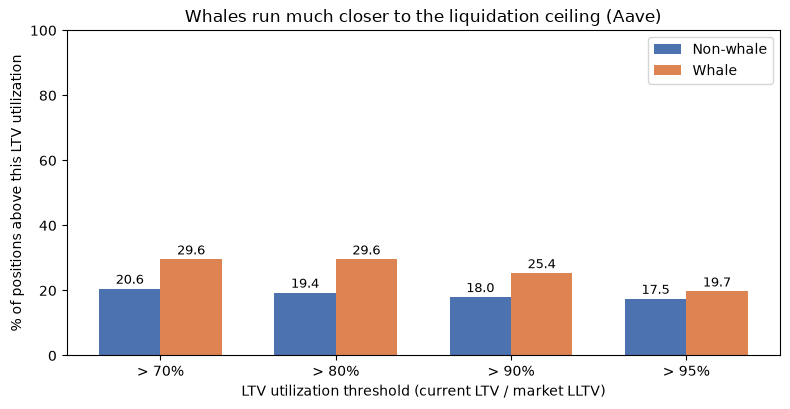

In [20]:
thresholds = [0.7, 0.8, 0.9, 0.95]
rows = []
for t in thresholds:
    tag = lltv_clean_whales["ltv_utilization"] > t
    result = tag.groupby(lltv_clean_whales["is_whale"]).mean() * 100
    rows.append({"threshold": t, "nonwhale": result.get(False, 0), "whale": result.get(True, 0)})

util_df = pd.DataFrame(rows)

x = np.arange(len(util_df))
w = 0.35

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - w/2, util_df["nonwhale"], width=w, color="#4C72B0", label="Non-whale")
ax.bar(x + w/2, util_df["whale"], width=w, color="#DD8452", label="Whale")
ax.set_xticks(x)
ax.set_xticklabels([f"> {int(t*100)}%" for t in util_df["threshold"]])
ax.set_ylabel("% of positions above this LTV utilization")
ax.set_xlabel("LTV utilization threshold (current LTV / market LLTV)")
ax.set_title("Whales run much closer to the liquidation ceiling (Aave)")
ax.set_ylim(0, 100)
for i, row in util_df.iterrows():
    ax.text(i - w/2, row["nonwhale"] + 1.5, f"{row['nonwhale']:.1f}", ha="center", fontsize=9)
    ax.text(i + w/2, row["whale"] + 1.5, f"{row['whale']:.1f}", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
save_fig("aave-leverage-utilization.png")
plt.show()

# Risks to them

In [21]:
# % price drop before hitting the liquidation threshold
lltv_clean_whales["price_drop_to_liquidation_pct"] = (
    (1 - lltv_clean_whales["ltv_utilization"]) * 100
).clip(lower=0)

risk_to_them = lltv_clean_whales.groupby("is_whale")["price_drop_to_liquidation_pct"].describe()
risk_to_them

,count,mean,std,min,25%,50%,75%,max
is_whale,,,,,,,,
False,739.0,77.878336,39.654768,0.0,82.582601,100.0,100.0,100.0
True,71.0,68.165061,43.589309,0.0,9.597415,100.0,100.0,100.0


In [22]:
for buffer in [1, 2, 5, 10]:
    at_risk = lltv_clean_whales["price_drop_to_liquidation_pct"] < buffer
    result = at_risk.groupby(lltv_clean_whales["is_whale"]).mean().round(3) * 100
    print(f"Within {buffer}% of liquidation: {result.to_dict()}")

Within 1% of liquidation: {False: 16.2, True: 12.7}
Within 2% of liquidation: {False: 16.6, True: 14.099999999999998}
Within 5% of liquidation: {False: 17.5, True: 19.7}
Within 10% of liquidation: {False: 18.0, True: 25.4}


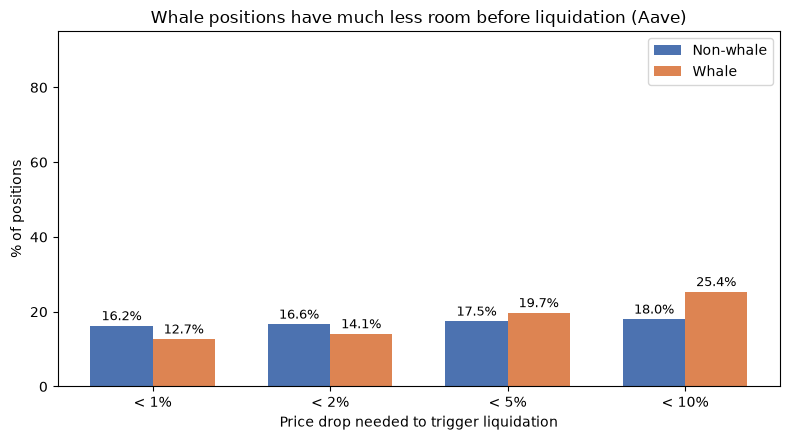

In [23]:
buffers = [1, 2, 5, 10]
rows = []
for b in buffers:
    at_risk = lltv_clean_whales["price_drop_to_liquidation_pct"] < b
    result = at_risk.groupby(lltv_clean_whales["is_whale"]).mean() * 100
    rows.append({"buffer": b, "nonwhale": result.get(False, 0), "whale": result.get(True, 0)})

dist_df = pd.DataFrame(rows)

x = np.arange(len(dist_df))
w = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, dist_df["nonwhale"], width=w, color="#4C72B0", label="Non-whale")
ax.bar(x + w/2, dist_df["whale"], width=w, color="#DD8452", label="Whale")
ax.set_xticks(x)
ax.set_xticklabels([f"< {b}%" for b in dist_df["buffer"]])
ax.set_ylabel("% of positions")
ax.set_xlabel("Price drop needed to trigger liquidation")
ax.set_title("Whale positions have much less room before liquidation (Aave)")
ax.set_ylim(0, 95)

for i, row in dist_df.iterrows():
    ax.text(i - w/2, row["nonwhale"] + 1.5, f"{row['nonwhale']:.1f}%", ha="center", fontsize=9)
    ax.text(i + w/2, row["whale"] + 1.5, f"{row['whale']:.1f}%", ha="center", fontsize=9)

ax.legend()
plt.tight_layout()
save_fig("aave-liquidation-distance.png")
plt.show()

## Risk to them: distance to liquidation

Percent price drop a wallet can absorb before the E-Mode threshold, (1 - utilisation) x 100.

| Buffer remaining | Non-whale | Whale |
|---|---|---|
| Within 1% | 16.2% | 12.7% |
| Within 2% | 16.6% | 14.1% |
| Within 5% | 17.5% | 19.7% |
| Within 10% | 18.0% | 25.4% |

The picture is mixed once Safe operators are included: at very tight buffers (1 to 2%) a
slightly larger share of non-whale operators sit on the edge, while at wider buffers (5 to
10%) whales dominate the danger zone, with 25.4% liquidating on a 10% move. A de-peg or
sharp sell-off well within normal volatility would still liquidate a quarter of whale
positions.

In [24]:
market_risk = lltv_clean_whales.groupby(["token_name"]).apply(
    lambda g: pd.Series({
        "total_collateral_usd": g["collateral_value_usd"].sum(),
        "at_risk_collateral_usd": g.loc[g["price_drop_to_liquidation_pct"] < 5, "collateral_value_usd"].sum(),
        "largest_position_usd": g["collateral_value_usd"].max(),
    })
).reset_index()

market_risk["at_risk_share_pct"] = (
    market_risk["at_risk_collateral_usd"] / market_risk["total_collateral_usd"] * 100
).round(1)
market_risk["largest_position_share_pct"] = (
    market_risk["largest_position_usd"] / market_risk["total_collateral_usd"] * 100
).round(1)

MIN_MARKET_SIZE = 100_000  # $100k threshold, adjust as needed
market_risk_filtered = market_risk[market_risk["total_collateral_usd"] > MIN_MARKET_SIZE]

market_risk_filtered.sort_values("total_collateral_usd", ascending=False)

,token_name,total_collateral_usd,at_risk_collateral_usd,largest_position_usd,at_risk_share_pct,largest_position_share_pct
0,sUSDe,1.087174e+09,1.557646e+08,1.964480e+08,14.3,18.1


## Risk to others: market-level exposure

Read across the whole sUSDe E-Mode position set (one cross-collateralised pool).

| Metric | Value |
|---|---|
| Total sUSDe E-Mode collateral | \$1,087.2M |
| Share within 5% of liquidation | 14.3% |
| Largest single wallet's share | 18.1% |

The largest wallet holds 18.1% of E-Mode collateral and 14.3% sits within a 5% move of
liquidation (diluted by the 816 collateral-only wallets). Less extreme than the worst
Morpho market (one wallet 82%), but still concentrated enough that a few liquidations could
cascade.

## Is the loop profitable?

A looper deposits YBS, borrows a stable against it, swaps back into YBS and repeats, which
only pays if collateral yield beats borrow cost. Per market:

`spread = native YBS APY + Aave supply APY - Aave borrow APY`

Supply APY is near zero (sUSDe is posted as collateral, not for supply yield). A positive
spread where whales concentrate means the leverage is rational rather than reckless.


In [25]:
# APY inputs pinned to the 2026-07-14 snapshot for reproducibility.
# native sUSDe: Ethena staking APY, DeFiLlama historical, 2026-07-14.
# supply: sUSDe is posted as collateral, so its Aave supply APY is ~0.
# borrow: Aave v3 variable borrow rate on 2026-07-14 from
# from_dune/aave_borrow_rates_snapshot.sql; falls back to the mid-June series if absent.
native_apy = 3.96
supply_apy = 0.0

BORROW_FALLBACK = {"USDT": 3.16, "USDC": 4.09, "USDe": 2.96}  # latest supervised series, mid-June 2026
borrow_path = Path("from_dune/aave_borrow_rates_2026_07_14.csv")
if borrow_path.exists():
    br = pd.read_csv(borrow_path)
    borrow_apys = dict(zip(br["symbol"], br["borrow_rate"].round(2)))
    borrow_src = "Dune snapshot 2026-07-14"
else:
    borrow_apys = BORROW_FALLBACK
    borrow_src = "fallback: latest supervised series, mid-June 2026"

print(f"Native sUSDe APY (2026-07-14): {native_apy}")
print(f"Aave sUSDe supply APY: {supply_apy}")
print(f"Aave borrow APYs [{borrow_src}]: {borrow_apys}")

Native sUSDe APY (2026-07-14): 3.96
Aave sUSDe supply APY: 0.0
Aave borrow APYs [Dune snapshot 2026-07-14]: {'USDC': 4.18, 'USDT': 3.45, 'USDe': 2.6}


In [26]:
apy_rows = []
for sym, bapy in borrow_apys.items():
    spread = native_apy + supply_apy - bapy
    apy_rows.append({
        "market_label": f"sUSDe → {sym}",
        "loan_token_symbol": sym,
        "native_apy": native_apy,
        "supply_apy": supply_apy,
        "borrow_apy": bapy,
        "net_spread": round(spread, 2),
        "is_profitable": spread > 0,
    })

apy_table = pd.DataFrame(apy_rows).sort_values("net_spread", ascending=False)
apy_table

,market_label,loan_token_symbol,native_apy,supply_apy,borrow_apy,net_spread,is_profitable
2,sUSDe → USDe,USDe,3.96,0.0,2.60,1.36,True
1,sUSDe → USDT,USDT,3.96,0.0,3.45,0.51,True
0,sUSDe → USDC,USDC,3.96,0.0,4.18,-0.22,False


## Are whales piling into positive-spread markets?

Checking the borrow markets where Aave sUSDe whales actually concentrate (USDT, USDC,
USDe). This cell weights the spread by whale collateral and needs the Aave export, so it
runs alongside the market breakdown above.

In [27]:
whale_apy = whale_market_share.merge(
    apy_table[["loan_token_symbol", "net_spread", "is_profitable"]],
    on="loan_token_symbol", how="left"
)

# borrow markets only: drop collateral-only (NONE) and any market without an APY spread,
# otherwise the collateral-only bucket dilutes the whale-weighted spread denominator
focus = whale_apy[(whale_apy["whale_collateral_usd"] > 0) & whale_apy["net_spread"].notna()].copy()
focus = focus.sort_values("whale_collateral_usd", ascending=False)

print("Spread in the borrow markets whales concentrate in:\n")
for _, r in focus.iterrows():
    verdict = "PROFITABLE" if r["net_spread"] > 0 else "unprofitable"
    print(f"  {r['token_name']:>9} \u2192 {r['loan_token_symbol']:<6}"
          f"  whale collateral ${r['whale_collateral_usd']:>14,.0f}"
          f"  net spread {r['net_spread']:+6.2f}%  ({verdict})")

w = focus["whale_collateral_usd"]
if w.sum() > 0:
    wavg = (focus["net_spread"] * w).sum() / w.sum()
    print(f"\nWhale-collateral-weighted net spread (borrow markets): {wavg:+.2f}%")


Spread in the borrow markets whales concentrate in:

      sUSDe → USDC    whale collateral $   237,592,277  net spread  -0.22%  (unprofitable)
      sUSDe → USDe    whale collateral $   221,271,484  net spread  +1.36%  (PROFITABLE)
      sUSDe → USDT    whale collateral $   115,868,038  net spread  +0.51%  (PROFITABLE)

Whale-collateral-weighted net spread (borrow markets): +0.54%


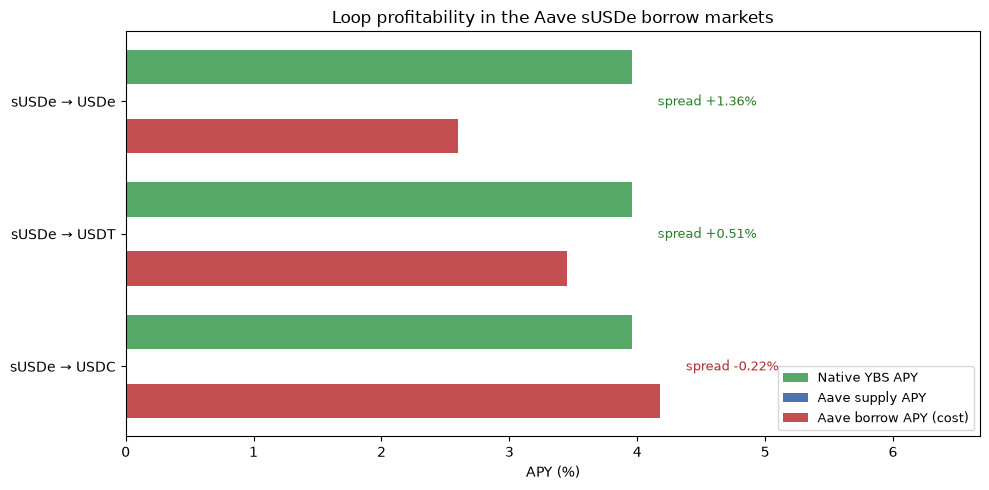

In [28]:
plot_df = apy_table.sort_values("net_spread", ascending=False).reset_index(drop=True)

y = np.arange(len(plot_df))[::-1]
h = 0.26

fig, ax = plt.subplots(figsize=(10, 5.0))
ax.barh(y + h, plot_df["native_apy"], height=h, label="Native YBS APY", color="#55A868")
ax.barh(y, plot_df["supply_apy"], height=h, label="Aave supply APY", color="#4C72B0")
ax.barh(y - h, plot_df["borrow_apy"], height=h, label="Aave borrow APY (cost)", color="#C44E52")
ax.set_yticks(y)
ax.set_yticklabels(plot_df["market_label"])
ax.set_xlabel("APY (%)")
ax.set_title("Loop profitability in the Aave sUSDe borrow markets")
for yi, row in zip(y, plot_df.itertuples()):
    m = max(row.native_apy, row.supply_apy, row.borrow_apy)
    ax.text(m + 0.2, yi, f"spread {row.net_spread:+.2f}%", va="center", fontsize=9,
            color=("#2a7d2a" if row.net_spread > 0 else "#b02a2a"))
ax.set_xlim(0, plot_df[["native_apy", "supply_apy", "borrow_apy"]].values.max() + 2.5)
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_fig("aave-apy-spread-whale-markets.png")
plt.show()

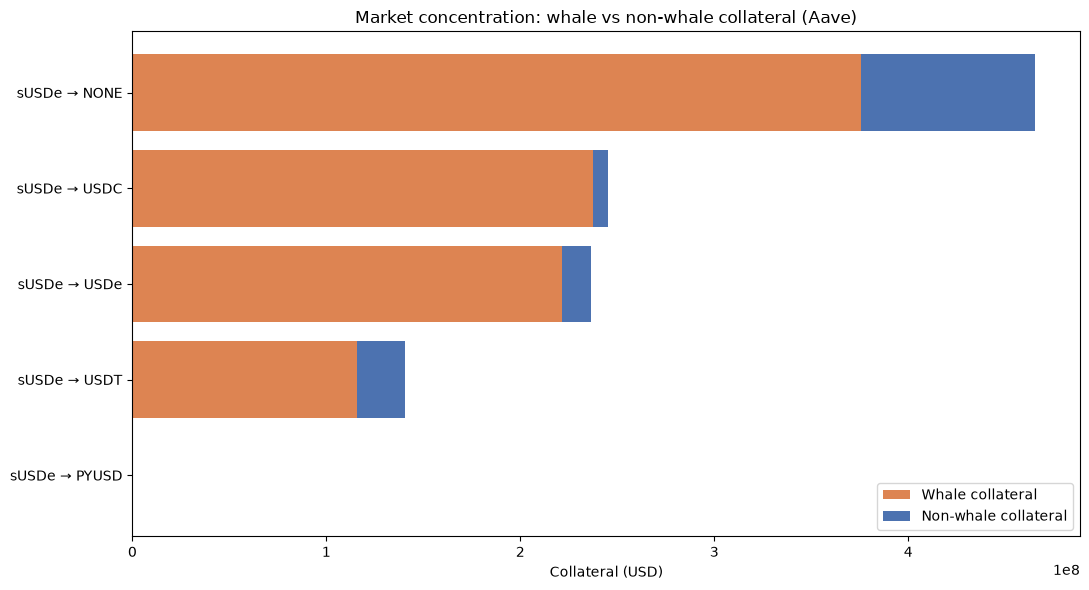

In [29]:
conc = whale_market_share.copy()
conc["market_label"] = conc["token_name"] + " → " + conc["loan_token_symbol"]
conc["nonwhale_collateral_usd"] = (conc["total_collateral_usd"] - conc["whale_collateral_usd"]).clip(lower=0)
conc = conc.sort_values("total_collateral_usd", ascending=False).head(12).iloc[::-1]

y = np.arange(len(conc))
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(y, conc["whale_collateral_usd"], color="#DD8452", label="Whale collateral")
ax.barh(y, conc["nonwhale_collateral_usd"], left=conc["whale_collateral_usd"], color="#4C72B0", label="Non-whale collateral")
ax.set_yticks(y)
ax.set_yticklabels(conc["market_label"])
ax.set_xlabel("Collateral (USD)")
ax.set_title("Market concentration: whale vs non-whale collateral (Aave)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

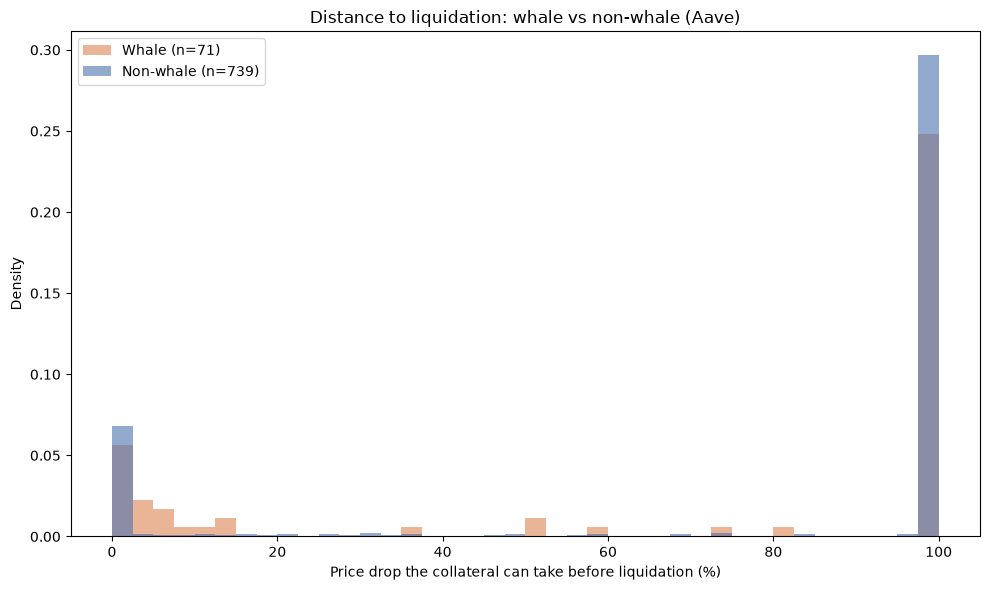

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(0, 100, 41)

for flag, label, color in [(True, "Whale", "#DD8452"), (False, "Non-whale", "#4C72B0")]:
    vals = lltv_clean_whales.loc[lltv_clean_whales["is_whale"] == flag, "price_drop_to_liquidation_pct"].dropna()
    ax.hist(vals, bins=bins, alpha=0.6, label=f"{label} (n={len(vals)})", color=color, density=True)

ax.set_xlabel("Price drop the collateral can take before liquidation (%)")
ax.set_ylabel("Density")
ax.set_title("Distance to liquidation: whale vs non-whale (Aave)")
ax.legend()

plt.tight_layout()
plt.show()